# Exploration of the January 2025 yellow taxi trips (training days)

This notebook looks at the staged trips from pickups on 2025-01-01 up to but not including 2025-01-25 (Jan 1 to 24). It is for exploring only. No pipeline code imports it.

The date filter is written once, as a temporary view, so no query below can reach January 25 to 31. The test week is never read, counted or plotted. The warehouse is opened read-only.

In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Project root = the folder with pyproject.toml (this notebook runs from notebooks/).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)  # DB_CONN holds a path relative to the project root
sys.path.insert(0, str(ROOT / "src"))

# Load DB_CONN from the root .env when it is not already set. The value is never printed.
if "DB_CONN" not in os.environ:
    for line in (ROOT / ".env").read_text().splitlines():
        line = line.strip()
        if line.startswith("DB_CONN="):
            os.environ["DB_CONN"] = line.split("=", 1)[1].strip().strip('"').strip("'")
print("DB_CONN set:", "DB_CONN" in os.environ)

from taxi_duration.db import connect

con = connect(read_only=True)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

def q(sql):
    return con.execute(sql).df()

def one(sql):
    return con.execute(sql).fetchone()
print("project root found, warehouse open read-only")

DB_CONN set: True
project root found, warehouse open read-only


## Training days view

All queries read from `train`, which keeps only pickups from 2025-01-01 up to but not including 2025-01-25. `trips` adds the duration in minutes (dropoff minus pickup), the pickup day and hour, and the weekend flag. It is built on `train`, so it has the same rows.

In [2]:
con.execute('''
CREATE OR REPLACE TEMP VIEW train AS
SELECT * FROM stg_trips
WHERE pickup_at >= '2025-01-01' AND pickup_at < '2025-01-25'
''')
con.execute('''
CREATE OR REPLACE TEMP VIEW trips AS
SELECT *,
       date_diff('second', pickup_at, dropoff_at) / 60.0 AS duration_min,
       CAST(pickup_at AS DATE) AS pickup_day,
       hour(pickup_at) AS pickup_hour,
       isodow(pickup_at) AS dow,
       isodow(pickup_at) >= 6 AS is_weekend
FROM train
''')
cols = [r[0] for r in con.execute("DESCRIBE stg_trips").fetchall()]
print(len(cols), "columns:", cols)
print(q("SELECT count(*) AS training_rows, min(pickup_at) AS first_pickup, max(pickup_at) AS last_pickup FROM train"))

20 columns: ['vendor_id', 'pickup_at', 'dropoff_at', 'passenger_count', 'trip_distance', 'rate_code_id', 'store_and_fwd_flag', 'pickup_zone_id', 'dropoff_zone_id', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'airport_fee', 'cbd_congestion_fee']
   training_rows first_pickup         last_pickup
0        2641485   2025-01-01 2025-01-24 23:59:59


In [3]:
last_pickup = one("SELECT max(pickup_at) FROM train")[0]
assert last_pickup < pd.Timestamp("2025-01-25"), last_pickup
print("ok: last pickup in the training view is", last_pickup)

ok: last pickup in the training view is 2025-01-24 23:59:59


## 1. Exact duplicates

Rows that are equal in all 20 source columns. The source has no key, so these cannot be told apart from two real trips that happen to be identical. The load keeps them and counts them. Here we look at how many there are and whether they cluster.

In [4]:
col_list = ", ".join(cols)
con.execute(f'''
CREATE OR REPLACE TEMP TABLE dup_groups AS
SELECT {col_list}, count(*) AS n FROM train GROUP BY {col_list} HAVING count(*) > 1
''')
total = one("SELECT count(*) FROM train")[0]
g = one("SELECT count(*), coalesce(sum(n), 0), coalesce(sum(n - 1), 0), coalesce(max(n), 0) FROM dup_groups")
dup_groups, rows_in_groups, extra_rows, largest = g
distinct_all = one(f"SELECT count(*) FROM (SELECT DISTINCT {col_list} FROM train)")[0]
print(pd.Series({
    "training rows": total,
    "distinct rows (all 20 columns)": distinct_all,
    "duplicate groups (size 2+)": dup_groups,
    "rows inside duplicate groups": rows_in_groups,
    "share of rows inside duplicate groups": rows_in_groups / total,
    "extra rows (rows minus distinct)": extra_rows,
    "share extra rows": extra_rows / total,
    "largest group size": largest,
}).to_string())
print()
print("Group size distribution")
print(q("SELECT n AS group_size, count(*) AS groups FROM dup_groups GROUP BY n ORDER BY n"))

training rows                           2,641,485.000
distinct rows (all 20 columns)          2,641,485.000
duplicate groups (size 2+)                      0.000
rows inside duplicate groups                    0.000
share of rows inside duplicate groups           0.000
extra rows (rows minus distinct)                0.000
share extra rows                                0.000
largest group size                              0.000

Group size distribution
Empty DataFrame
Columns: [group_size, groups]
Index: []


In [5]:
print("By vendor (extra rows = rows beyond the first in each group)")
print(q('''
SELECT d.vendor_id, count(*) AS groups, sum(n - 1) AS extra_rows,
       round(100.0 * sum(n - 1) / sum(sum(n - 1)) OVER (), 2) AS pct_of_extra_rows
FROM dup_groups d GROUP BY d.vendor_id ORDER BY extra_rows DESC
'''))
print("Training rows by vendor, for comparison")
print(q("SELECT vendor_id, count(*) AS rows, round(100.0 * count(*) / sum(count(*)) OVER (), 2) AS pct_of_rows FROM train GROUP BY vendor_id ORDER BY rows DESC"))
print("By pickup day")
print(q('''
SELECT CAST(pickup_at AS DATE) AS day, count(*) AS groups, sum(n - 1) AS extra_rows
FROM dup_groups GROUP BY day ORDER BY day
'''))
print("By pickup hour")
print(q('''
SELECT hour(pickup_at) AS hour, count(*) AS groups, sum(n - 1) AS extra_rows
FROM dup_groups GROUP BY hour ORDER BY hour
'''))
print("Duplicate groups with zero distance, zero or negative fare, or the same pickup and dropoff time")
print(q('''
SELECT count(*) FILTER (trip_distance = 0) AS zero_distance_groups,
       count(*) FILTER (fare_amount <= 0) AS nonpositive_fare_groups,
       count(*) FILTER (pickup_at = dropoff_at) AS zero_duration_groups,
       count(*) AS all_groups
FROM dup_groups
'''))
print("Ten largest groups")
print(q("SELECT n, vendor_id, pickup_at, dropoff_at, trip_distance, pickup_zone_id, dropoff_zone_id, fare_amount FROM dup_groups ORDER BY n DESC, pickup_at LIMIT 10"))

By vendor (extra rows = rows beyond the first in each group)
Empty DataFrame
Columns: [vendor_id, groups, extra_rows, pct_of_extra_rows]
Index: []
Training rows by vendor, for comparison
   vendor_id     rows  pct_of_rows
0          2  2069956       78.360
1          1   570756       21.610
2          7      499        0.020
3          6      274        0.010
By pickup day
Empty DataFrame
Columns: [day, groups, extra_rows]
Index: []
By pickup hour
Empty DataFrame
Columns: [hour, groups, extra_rows]
Index: []
Duplicate groups with zero distance, zero or negative fare, or the same pickup and dropoff time
   zero_distance_groups  nonpositive_fare_groups  zero_duration_groups  all_groups
0                     0                        0                     0           0
Ten largest groups
Empty DataFrame
Columns: [n, vendor_id, pickup_at, dropoff_at, trip_distance, pickup_zone_id, dropoff_zone_id, fare_amount]
Index: []


## 2. trip_distance and implied speed

Distance is in miles. Duration is dropoff minus pickup in minutes. Implied speed in mph is distance divided by duration in hours, for duration above zero. The brief keeps only trips of 1 to 60 minutes. Here that scope is only counted, not applied.

In [6]:
print(q('''
SELECT count(*) AS rows,
       count(*) FILTER (trip_distance IS NULL) AS null_distance,
       count(*) FILTER (trip_distance < 0) AS negative,
       count(*) FILTER (trip_distance = 0) AS zero,
       count(*) FILTER (trip_distance > 0) AS positive
FROM trips
'''))
qs = [0.0, 0.01, 0.05, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999, 0.9999, 1.0]
vals = one("SELECT " + ", ".join(f"quantile_cont(trip_distance, {p})" for p in qs) + " FROM trips")
print("trip_distance quantiles, all training rows (miles)")
print(pd.Series(vals, index=[f"p{p*100:g}" for p in qs]).to_string())
print()
print("Top 20 distances")
print(q("SELECT trip_distance, duration_min, round(trip_distance / NULLIF(duration_min / 60.0, 0), 1) AS mph, pickup_zone_id, dropoff_zone_id, pickup_at FROM trips ORDER BY trip_distance DESC LIMIT 20"))

      rows  null_distance  negative   zero  positive
0  2641485              0         0  67392   2574093


trip_distance quantiles, all training rows (miles)
p0             0.000
p1             0.000
p5             0.390
p25            0.980
p50            1.670
p75            3.110
p90            7.900
p95           12.170
p99           19.620
p99.9         29.050
p99.99        60.309
p100     276,423.570

Top 20 distances
    trip_distance  duration_min           mph  pickup_zone_id  dropoff_zone_id           pickup_at
0     276,423.570         9.000 1,842,823.800             161              170 2025-01-22 21:04:00
1     276,099.950         7.000 2,366,571.000             224              233 2025-01-19 14:51:00
2     222,167.490        26.000   512,694.200              52              144 2025-01-21 09:19:00
3     206,137.990        24.000   515,345.000             263               48 2025-01-16 10:47:00
4     189,687.430        18.000   632,291.400             246              164 2025-01-14 19:18:00
5     181,139.990         6.000 1,811,399.900             100               90 2025-0

In [7]:
print("Duration buckets (minutes), all training rows")
print(q('''
SELECT
  count(*) AS rows,
  count(*) FILTER (duration_min = 0) AS zero_duration,
  count(*) FILTER (duration_min > 0 AND duration_min < 1) AS under_1_min_positive,
  count(*) FILTER (duration_min < 1) AS under_1_min_incl_zero,
  count(*) FILTER (duration_min >= 1 AND duration_min <= 60) AS in_scope_1_to_60,
  count(*) FILTER (duration_min > 60) AS over_60_min,
  count(*) FILTER (duration_min > 24 * 60) AS over_24_h
FROM trips
'''))
r = one("SELECT count(*) FILTER (duration_min < 1 OR duration_min > 60), count(*) FROM trips")
print(f"outside 1 to 60 minutes: {r[0]} of {r[1]} training rows ({r[0] / r[1]:.4%}); not applied here")
print()
print("Duration quantiles (minutes), all training rows")
dq = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999, 0.9999, 1.0]
dv = one("SELECT " + ", ".join(f"quantile_cont(duration_min, {p})" for p in dq) + " FROM trips")
print(pd.Series(dv, index=[f"p{p*100:g}" for p in dq]).to_string())

Duration buckets (minutes), all training rows
      rows  zero_duration  under_1_min_positive  under_1_min_incl_zero  in_scope_1_to_60  over_60_min  over_24_h
0  2641485           1057                 29589                  30646           2587420        23419         15
outside 1 to 60 minutes: 54065 of 2641485 training rows (2.0468%); not applied here

Duration quantiles (minutes), all training rows


p1           0.650
p5           3.333
p25          7.217
p50         11.633
p75         18.283
p95         36.400
p99         58.517
p99.9       98.192
p99.99   1,428.964
p100     5,626.317


In [8]:
print("Implied speed (mph), duration > 0: counts above thresholds")
print(q('''
SELECT
  count(*) AS rows_with_duration,
  count(*) FILTER (trip_distance / (duration_min / 60.0) > 80) AS above_80,
  count(*) FILTER (trip_distance / (duration_min / 60.0) > 100) AS above_100,
  count(*) FILTER (trip_distance / (duration_min / 60.0) > 150) AS above_150
FROM trips WHERE duration_min > 0
'''))
print("Same, only for the 1 to 60 minute trips")
print(q('''
SELECT
  count(*) AS rows_in_scope,
  count(*) FILTER (trip_distance / (duration_min / 60.0) > 80) AS above_80,
  count(*) FILTER (trip_distance / (duration_min / 60.0) > 100) AS above_100,
  count(*) FILTER (trip_distance / (duration_min / 60.0) > 150) AS above_150
FROM trips WHERE duration_min BETWEEN 1 AND 60
'''))
print("Distance problems inside the 1 to 60 minute trips")
print(q('''
SELECT count(*) AS rows_in_scope,
       count(*) FILTER (trip_distance = 0) AS zero_distance,
       count(*) FILTER (trip_distance < 0) AS negative_distance,
       count(*) FILTER (trip_distance > 50) AS over_50_miles,
       count(*) FILTER (trip_distance > 0 AND trip_distance < 0.1) AS under_0_1_mile
FROM trips WHERE duration_min BETWEEN 1 AND 60
'''))
print("Implied speed quantiles (mph), 1 to 60 minute trips with distance > 0")
sq = [0.01, 0.5, 0.99, 0.999, 0.9999, 1.0]
sv = one("SELECT " + ", ".join(f"quantile_cont(trip_distance / (duration_min / 60.0), {p})" for p in sq) + " FROM trips WHERE duration_min BETWEEN 1 AND 60 AND trip_distance > 0")
print(pd.Series(sv, index=[f"p{p*100:g}" for p in sq]).to_string())
print()
print("Top 20 implied speeds, duration > 0")
print(q("SELECT round(trip_distance / (duration_min / 60.0), 1) AS mph, trip_distance, round(duration_min, 2) AS duration_min, pickup_zone_id, dropoff_zone_id FROM trips WHERE duration_min > 0 ORDER BY mph DESC LIMIT 20"))

Implied speed (mph), duration > 0: counts above thresholds
   rows_with_duration  above_80  above_100  above_150
0             2640428       766        704        616
Same, only for the 1 to 60 minute trips
   rows_in_scope  above_80  above_100  above_150
0        2587420       228        190        142
Distance problems inside the 1 to 60 minute trips
   rows_in_scope  zero_distance  negative_distance  over_50_miles  under_0_1_mile
0        2587420          46620                  0            117            9568
Implied speed quantiles (mph), 1 to 60 minute trips with distance > 0
p1               2.820
p50              9.689
p99             35.750
p99.9           46.191
p99.99          69.541
p100     3,722,496.900

Top 20 implied speeds, duration > 0
             mph  trip_distance  duration_min  pickup_zone_id  dropoff_zone_id
0  3,722,496.900    124,083.230         2.000              74               75
1  2,366,571.000    276,099.950         7.000             224              233

## 3. Zones 264 and 265

In the TLC zone lookup, 264 is Unknown and 265 is Outside of NYC (or N/A). Valid regular zones run from 1 to 263. Duration and distance summaries below use only the 1 to 60 minute trips so the groups are comparable; counts use all training rows.

In [9]:
print("Zone counts as pickup and dropoff, all training rows")
print(q('''
SELECT
  count(*) AS rows,
  count(*) FILTER (pickup_zone_id IN (264, 265)) AS pickup_264_265,
  count(*) FILTER (pickup_zone_id = 264) AS pickup_264,
  count(*) FILTER (pickup_zone_id = 265) AS pickup_265,
  count(*) FILTER (dropoff_zone_id IN (264, 265)) AS dropoff_264_265,
  count(*) FILTER (dropoff_zone_id = 264) AS dropoff_264,
  count(*) FILTER (dropoff_zone_id = 265) AS dropoff_265,
  count(*) FILTER (pickup_zone_id IN (264, 265) OR dropoff_zone_id IN (264, 265)) AS either_264_265
FROM trips
'''))
share = q('''
SELECT
  100.0 * count(*) FILTER (pickup_zone_id IN (264, 265)) / count(*) AS pickup_pct,
  100.0 * count(*) FILTER (dropoff_zone_id IN (264, 265)) / count(*) AS dropoff_pct,
  100.0 * count(*) FILTER (pickup_zone_id IN (264, 265) OR dropoff_zone_id IN (264, 265)) / count(*) AS either_pct
FROM trips
''')
print("Share of training rows (percent)")
print(share)
print()
print("Zone ids outside 1 to 263, other than 264 and 265, and nulls")
print(q('''
SELECT 'pickup' AS side, pickup_zone_id AS zone_id, count(*) AS rows FROM trips
WHERE pickup_zone_id IS NULL OR pickup_zone_id < 1 OR pickup_zone_id > 265 GROUP BY ALL
UNION ALL
SELECT 'dropoff', dropoff_zone_id, count(*) FROM trips
WHERE dropoff_zone_id IS NULL OR dropoff_zone_id < 1 OR dropoff_zone_id > 265 GROUP BY ALL
'''))
print("Distinct zone ids: pickup min/max, dropoff min/max")
print(q("SELECT min(pickup_zone_id) AS pu_min, max(pickup_zone_id) AS pu_max, min(dropoff_zone_id) AS do_min, max(dropoff_zone_id) AS do_max FROM trips"))

Zone counts as pickup and dropoff, all training rows
      rows  pickup_264_265  pickup_264  pickup_265  dropoff_264_265  dropoff_264  dropoff_265  either_264_265
0  2641485            7326        6212        1114            18669         9245         9424           21948
Share of training rows (percent)
   pickup_pct  dropoff_pct  either_pct
0       0.277        0.707       0.831

Zone ids outside 1 to 263, other than 264 and 265, and nulls
Empty DataFrame
Columns: [side, zone_id, rows]
Index: []
Distinct zone ids: pickup min/max, dropoff min/max
   pu_min  pu_max  do_min  do_max
0       1     265       1     265


In [10]:
summary_sql = '''
SELECT {label} AS grp, count(*) AS rows,
       round(median(duration_min), 2) AS median_min, round(avg(duration_min), 2) AS mean_min,
       round(median(trip_distance), 2) AS median_miles, round(avg(trip_distance), 2) AS mean_miles,
       count(*) FILTER (trip_distance = 0) AS zero_distance
FROM trips WHERE duration_min BETWEEN 1 AND 60
GROUP BY grp ORDER BY grp
'''
print("As pickup zone, 1 to 60 minute trips")
print(q(summary_sql.format(label="CASE WHEN pickup_zone_id = 264 THEN 'pickup 264' WHEN pickup_zone_id = 265 THEN 'pickup 265' ELSE 'other pickup' END")))
print("As dropoff zone, 1 to 60 minute trips")
print(q(summary_sql.format(label="CASE WHEN dropoff_zone_id = 264 THEN 'dropoff 264' WHEN dropoff_zone_id = 265 THEN 'dropoff 265' ELSE 'other dropoff' END")))
print("Trips with 264 or 265 on either side vs neither")
print(q(summary_sql.format(label="CASE WHEN pickup_zone_id IN (264, 265) OR dropoff_zone_id IN (264, 265) THEN 'has 264/265' ELSE 'neither' END")))

As pickup zone, 1 to 60 minute trips


            grp     rows  median_min  mean_min  median_miles  mean_miles  zero_distance
0  other pickup  2581099      11.650    14.200         1.670       6.050          46433
1    pickup 264     5901      11.480    14.490         1.700       3.310             99
2    pickup 265      420      13.760    16.040         5.480       8.450             88
As dropoff zone, 1 to 60 minute trips
             grp     rows  median_min  mean_min  median_miles  mean_miles  zero_distance
0    dropoff 264     8282      10.900    13.260         1.600       2.620            122
1    dropoff 265     7616      29.350    30.970        14.430      15.770            111
2  other dropoff  2571522      11.630    14.160         1.670       6.020          46387
Trips with 264 or 265 on either side vs neither


           grp     rows  median_min  mean_min  median_miles  mean_miles  zero_distance
0  has 264/265    19094      17.180    20.720         3.600       8.130            265
1      neither  2568326      11.630    14.150         1.670       6.030          46355


## 4. passenger_count

Value counts over all training rows, with null shown as its own row. Not a feature candidate in the mart (it stays in staging), so this is for the record.

In [11]:
print(q('''
SELECT passenger_count, count(*) AS rows, round(100.0 * count(*) / sum(count(*)) OVER (), 3) AS pct
FROM trips GROUP BY passenger_count ORDER BY passenger_count NULLS FIRST
'''))
print(q('''
SELECT count(*) FILTER (passenger_count IS NULL) AS null_count,
       count(*) FILTER (passenger_count = 0) AS zero,
       count(*) FILTER (passenger_count > 6) AS above_6,
       count(*) FILTER (passenger_count BETWEEN 1 AND 6) AS one_to_six
FROM trips
'''))

    passenger_count     rows    pct
0              <NA>   397120 15.034
1                 0    19230  0.728
2                 1  1765244 66.828
3                 2   316173 11.970
4                 3    72334  2.738
5                 4    48329  1.830
6                 5    13722  0.519
7                 6     9320  0.353
8                 7        3  0.000
9                 8        7  0.000
10                9        3  0.000
   null_count   zero  above_6  one_to_six
0      397120  19230       13     2225122


## 5. Congestion pricing from 2025-01-05

The central business district congestion charge started on Sunday 2025-01-05. Below, duration in minutes is compared before (Jan 1 to 4) and after (Jan 5 to 24). Only trips of 1 to 60 minutes are used, which is the scope in the brief.

Things that make this comparison weak, so read the numbers with care:
- Only 4 days are before the charge (Wed Jan 1 to Sat Jan 4), against 20 days after.
- Jan 1 is New Year's Day, a holiday with unusual traffic and trip mix.
- The weekday mix differs: before has 1 Wednesday, 1 Thursday, 1 Friday and 1 Saturday and no Sunday to Tuesday. After has all weekdays, several times each. So weekday and weekend are split below, and a matched-weekday comparison follows.
- Other differences between days (weather, events, Jan 20 being a public holiday) are not controlled.
- `cbd_congestion_fee` is a post-trip column. It is used here only to see which trips were charged. It is never a model feature.

In [12]:
con.execute('''
CREATE OR REPLACE TEMP VIEW cp AS
SELECT *, CASE WHEN pickup_at < '2025-01-05' THEN 'before' ELSE 'after' END AS period
FROM trips WHERE duration_min BETWEEN 1 AND 60
''')
print("Days in each period (all rows in view)")
print(q("SELECT period, count(DISTINCT pickup_day) AS days, count(*) AS trips, min(pickup_day) AS first_day, max(pickup_day) AS last_day FROM cp GROUP BY period ORDER BY period DESC"))
print("Weekday mix: days per weekday name in each period")
print(q("SELECT period, dayname(pickup_day) AS weekday, count(DISTINCT pickup_day) AS days FROM cp GROUP BY ALL ORDER BY period DESC, min(dow)"))

stat_sql = '''
SELECT {grp} period, count(*) AS trips,
       round(median(duration_min), 2) AS median_min, round(avg(duration_min), 2) AS mean_min,
       round(quantile_cont(duration_min, 0.25), 2) AS p25_min, round(quantile_cont(duration_min, 0.75), 2) AS p75_min,
       round(median(trip_distance), 2) AS median_miles
FROM cp {where} GROUP BY {gb} ORDER BY {ob}
'''
print("All 1 to 60 minute trips")
print(q(stat_sql.format(grp="", where="", gb="period", ob="period DESC")))
print("Weekdays (Mon to Fri) vs weekend (Sat, Sun)")
print(q(stat_sql.format(grp="CASE WHEN is_weekend THEN 'weekend' ELSE 'weekday' END AS daytype,", where="", gb="ALL", ob="daytype, period DESC")))

Days in each period (all rows in view)
   period  days    trips  first_day   last_day
0  before     4   355540 2025-01-01 2025-01-04
1   after    20  2231880 2025-01-05 2025-01-24
Weekday mix: days per weekday name in each period


    period    weekday  days
0   before  Wednesday     1
1   before   Thursday     1
2   before     Friday     1
3   before   Saturday     1
4    after     Monday     3
5    after    Tuesday     3
6    after  Wednesday     3
7    after   Thursday     3
8    after     Friday     3
9    after   Saturday     2
10   after     Sunday     3
All 1 to 60 minute trips
   period    trips  median_min  mean_min  p25_min  p75_min  median_miles
0  before   355540      12.170    14.900    7.370   19.470         1.790
1   after  2231880      11.580    14.090    7.320   17.950         1.650
Weekdays (Mon to Fri) vs weekend (Sat, Sun)


   daytype  period    trips  median_min  mean_min  p25_min  p75_min  median_miles
0  weekday  before   259395      12.300    15.070    7.450   19.670         1.820
1  weekday   after  1698496      11.750    14.310    7.430   18.180         1.600
2  weekend  before    96145      11.800    14.430    7.150   18.930         1.680
3  weekend   after   533384      11.070    13.400    7.000   17.170         1.800


In [13]:
print("Minutes per mile, trips with distance > 0.5 (1 to 60 minutes)")
mpm = '''
SELECT {grp} period, count(*) AS trips,
       round(median(duration_min / trip_distance), 3) AS median_min_per_mile,
       round(avg(duration_min / trip_distance), 3) AS mean_min_per_mile,
       round(quantile_cont(duration_min / trip_distance, 0.25), 3) AS p25,
       round(quantile_cont(duration_min / trip_distance, 0.75), 3) AS p75
FROM cp WHERE trip_distance > 0.5 {gb}
ORDER BY {ob}
'''
print(q(mpm.format(grp="", gb="GROUP BY period", ob="period DESC")))
print(q(mpm.format(grp="CASE WHEN is_weekend THEN 'weekend' ELSE 'weekday' END AS daytype,", gb="GROUP BY ALL", ob="daytype, period DESC")))

Minutes per mile, trips with distance > 0.5 (1 to 60 minutes)
   period    trips  median_min_per_mile  mean_min_per_mile   p25   p75
0  before   335804                5.826              6.377 4.156 7.679
1   after  2074815                6.126              6.487 4.538 7.893
   daytype  period    trips  median_min_per_mile  mean_min_per_mile   p25   p75
0  weekday  before   245064                5.748              6.271 4.074 7.580
1  weekday   after  1566254                6.348              6.708 4.708 8.162
2  weekend  before    90740                6.035              6.662 4.382 7.961
3  weekend   after   508561                5.537              5.808 4.128 7.027


In [14]:
hourly = q('''
SELECT CASE WHEN is_weekend THEN 'weekend' ELSE 'weekday' END AS daytype, pickup_hour AS hour, period,
       count(*) AS trips, median(duration_min) AS median_min, avg(duration_min) AS mean_min,
       quantile_cont(duration_min, 0.25) AS p25_min, quantile_cont(duration_min, 0.75) AS p75_min
FROM cp GROUP BY ALL
''')
wide = hourly.pivot(index=["daytype", "hour"], columns="period", values=["trips", "median_min", "mean_min", "p25_min", "p75_min"])
wide.columns = [f"{a}_{b}" for a, b in wide.columns]
wide["median_diff"] = wide["median_min_after"] - wide["median_min_before"]
pd.set_option("display.max_rows", 100)
print("By hour of day, weekday and weekend separately (diff = after minus before)")
print(wide[["trips_before", "trips_after", "median_min_before", "median_min_after", "median_diff", "mean_min_before", "mean_min_after", "p25_min_before", "p25_min_after", "p75_min_before", "p75_min_after"]].round(2))

By hour of day, weekday and weekend separately (diff = after minus before)
              trips_before  trips_after  median_min_before  median_min_after  median_diff  mean_min_before  mean_min_after  p25_min_before  p25_min_after  \
daytype hour                                                                                                                                                
weekday 0        9,762.000   24,910.000             13.320            11.130       -2.180           16.010          13.750           7.770          6.800   
        1        9,590.000   11,560.000             13.480            10.670       -2.820           15.630          13.290           8.250          6.350   
        2        7,841.000    6,381.000             13.130            10.230       -2.900           14.760          12.580           8.080          6.120   
        3        5,334.000    4,440.000             12.080            10.670       -1.420           13.860          13.090           7.420  

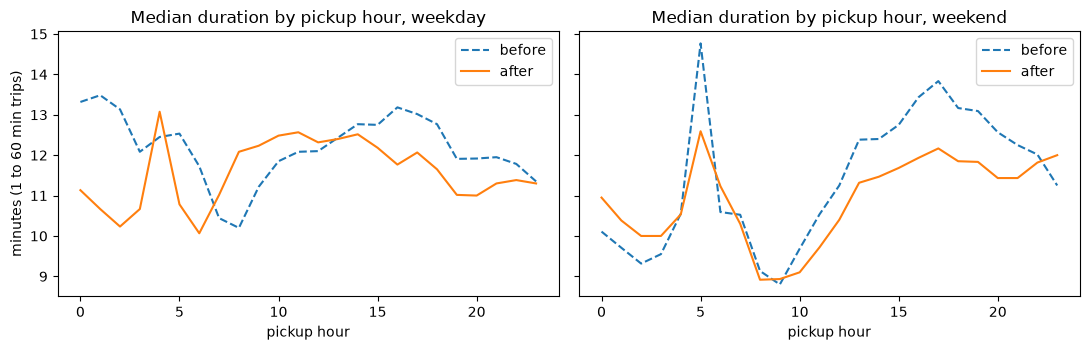

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, dt in zip(axes, ["weekday", "weekend"]):
    sub = hourly[hourly.daytype == dt]
    for per, style in [("before", "--"), ("after", "-")]:
        s = sub[sub.period == per].sort_values("hour")
        ax.plot(s["hour"], s["median_min"], style, label=per)
    ax.set_title(f"Median duration by pickup hour, {dt}")
    ax.set_xlabel("pickup hour")
    ax.legend()
axes[0].set_ylabel("minutes (1 to 60 min trips)")
plt.tight_layout()
plt.show()

### Matched weekdays

Thursday Jan 2 and Friday Jan 3 (before the charge) against the later Thursdays (Jan 9, 16, 23) and Fridays (Jan 10, 17, 24). This keeps the weekday the same, but it is still two single days against several days, and Jan 2 may still carry holiday effects.

In [16]:
print("Per day, Thursdays and Fridays")
print(q('''
SELECT pickup_day, dayname(pickup_day) AS weekday, period, count(*) AS trips,
       round(median(duration_min), 2) AS median_min, round(avg(duration_min), 2) AS mean_min,
       round(quantile_cont(duration_min, 0.25), 2) AS p25_min, round(quantile_cont(duration_min, 0.75), 2) AS p75_min,
       round(median(trip_distance), 2) AS median_miles
FROM cp WHERE dow IN (4, 5) GROUP BY ALL ORDER BY pickup_day
'''))
print("Matched weekday, pooled by weekday and period")
print(q('''
SELECT dayname(pickup_day) AS weekday, period, count(DISTINCT pickup_day) AS days, count(*) AS trips,
       round(median(duration_min), 2) AS median_min, round(avg(duration_min), 2) AS mean_min,
       round(quantile_cont(duration_min, 0.25), 2) AS p25_min, round(quantile_cont(duration_min, 0.75), 2) AS p75_min,
       round(median(trip_distance), 2) AS median_miles
FROM cp WHERE dow IN (4, 5) GROUP BY ALL ORDER BY weekday, period DESC
'''))
print("Matched weekday (Thu and Fri together), minutes per mile for distance > 0.5")
print(q('''
SELECT period, count(*) AS trips, round(median(duration_min / trip_distance), 3) AS median_min_per_mile
FROM cp WHERE dow IN (4, 5) AND trip_distance > 0.5 GROUP BY period ORDER BY period DESC
'''))
mh = q('''
SELECT pickup_hour AS hour, period, count(*) AS trips, median(duration_min) AS median_min
FROM cp WHERE dow IN (4, 5) GROUP BY ALL
''')
mw = mh.pivot(index="hour", columns="period", values=["trips", "median_min"])
mw.columns = [f"{a}_{b}" for a, b in mw.columns]
mw["median_diff"] = mw["median_min_after"] - mw["median_min_before"]
print("Thu and Fri together by hour (before = Jan 2 and 3 only)")
print(mw.round(2))

Per day, Thursdays and Fridays
  pickup_day   weekday  period   trips  median_min  mean_min  p25_min  p75_min  median_miles
0 2025-01-02  Thursday  before   82288      12.420    15.480    7.480   20.100         1.720
1 2025-01-03    Friday  before   88771      12.020    14.860    7.350   19.100         1.680
2 2025-01-09  Thursday   after  116469      11.800    14.270    7.400   18.250         1.580
3 2025-01-10    Friday   after  109210      11.750    14.400    7.420   18.250         1.610
4 2025-01-16  Thursday   after  135768      12.230    14.730    7.780   18.750         1.610
5 2025-01-17    Friday   after  117666      12.100    14.630    7.670   18.620         1.630
6 2025-01-23  Thursday   after  135474      12.350    14.690    7.850   18.750         1.590
7 2025-01-24    Friday   after  126638      12.100    14.550    7.700   18.530         1.600
Matched weekday, pooled by weekday and period
    weekday  period  days   trips  median_min  mean_min  p25_min  p75_min  median_mile

In [17]:
print("Share of trips with a congestion fee above 0 (cbd_congestion_fee), by day. Used only to see which trips were charged.")
fee = q('''
SELECT pickup_day, dayname(pickup_day) AS weekday, count(*) AS trips,
       count(*) FILTER (cbd_congestion_fee > 0) AS charged,
       round(100.0 * count(*) FILTER (cbd_congestion_fee > 0) / count(*), 2) AS pct_charged,
       count(*) FILTER (cbd_congestion_fee IS NULL) AS fee_null
FROM trips GROUP BY ALL ORDER BY pickup_day
''')
print(fee)
print("Distinct cbd_congestion_fee values")
print(q("SELECT cbd_congestion_fee, count(*) AS rows FROM trips GROUP BY 1 ORDER BY 2 DESC LIMIT 10"))
print("Duration of 1 to 60 minute trips after Jan 5, charged vs not charged (confounded by where the trip runs)")
print(q('''
SELECT cbd_congestion_fee > 0 AS charged, count(*) AS trips, round(median(duration_min), 2) AS median_min,
       round(median(trip_distance), 2) AS median_miles, round(median(duration_min / NULLIF(trip_distance, 0)) , 3) AS median_min_per_mile_all
FROM cp WHERE period = 'after' GROUP BY 1 ORDER BY 1
'''))

Share of trips with a congestion fee above 0 (cbd_congestion_fee), by day. Used only to see which trips were charged.
   pickup_day    weekday   trips  charged  pct_charged  fee_null
0  2025-01-01  Wednesday   90186        0        0.000         0
1  2025-01-02   Thursday   84827        0        0.000         0
2  2025-01-03     Friday   91247        0        0.000         0
3  2025-01-04   Saturday   97804      401        0.410         0
4  2025-01-05     Sunday   79623    51509       64.690         0
5  2025-01-06     Monday   80119    51802       64.660         0
6  2025-01-07    Tuesday  100637    69425       68.990         0
7  2025-01-08  Wednesday  113892    81062       71.170         0
8  2025-01-09   Thursday  119279    85150       71.390         0
9  2025-01-10     Friday  111493    78626       70.520         0
10 2025-01-11   Saturday  121963    92556       75.890         0
11 2025-01-12     Sunday  102507    76132       74.270         0
12 2025-01-13     Monday  100484    7

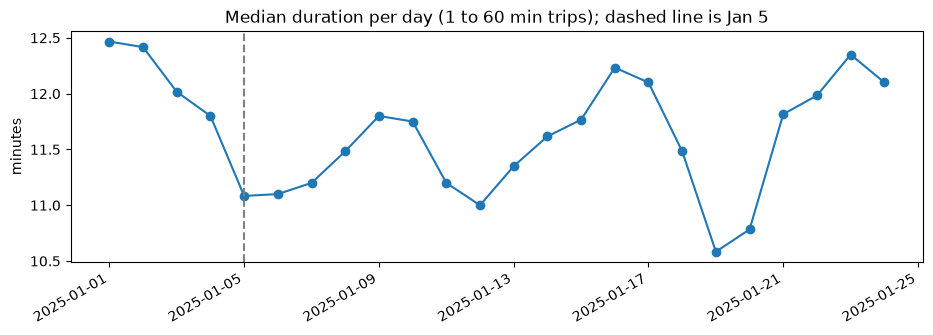

In [18]:
daily = q('''
SELECT pickup_day, median(duration_min) AS median_min FROM cp GROUP BY 1 ORDER BY 1
''')
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(daily["pickup_day"], daily["median_min"], marker="o")
ax.axvline(pd.Timestamp("2025-01-05"), color="grey", linestyle="--")
ax.set_title("Median duration per day (1 to 60 min trips); dashed line is Jan 5")
ax.set_ylabel("minutes")
fig.autofmt_xdate()
plt.show()

In [19]:
con.close()
print("connection closed")

connection closed
